# Notebook 03: Pré-processamento e Engenharia de Dados (Preparação para Clusterização)

## 1. Introdução e Metodologia Científica (Pós-Anonimização)

Este documento executa a etapa de engenharia, saneamento e estruturação de dados da base de **Inscrições**. O pipeline foi estritamente desenhado para garantir a integridade da futura fusão (*merge*) com dados de desempenho e a robustez estatística necessária para algoritmos de clusterização (K-Means).

O processo adere às normas **LGPD (Lei 13.709/2018)** e **ISO/IEC 25012**, operando sob a premissa de *Privacy by Design*.

### 1.1. Governança e Consumo do Artefato Seguro
Diferente das extrações brutas, este notebook opera em um ambiente *Clean Room*. A base consumida aqui (`00_inscricoes_anonimizadas.parquet`) já passou pelo pipeline de pseudonimização determinística (Notebook 00). Os identificadores civis foram expurgados, e a matriz opera exclusivamente via chaves relacionais seguras (`id_inscricoes` e `id_discente_anonimo`).

### 1.2. Abordagens de Saneamento Metodológico
* **Idempotência (Golden Record):** Remoção de logs duplicados retendo a intenção cronológica final do usuário.
* **Tratamento de Nulos (MNAR):** Valores nulos estruturais não são descartados, mas sim tagueados (*Flags de Auditoria*), pois a "ausência de informação" pode ser uma característica definidora de um cluster.
* **Winsorização Condicional Agrupada:** Tratamento de *outliers* de carga horária respeitando a distribuição interna de cada curso, evitando cortes globais arbitrários.

### 1.3. Pipeline de Execução (Roadmap Atualizado)
1. **Setup e Ingestão Segura:** Carga do artefato `.parquet` e validação do *Kill Switch* da LGPD.
2. **Eixo 1 - Saneamento Temporal:** Coerção de datas e deduplicação lógica (*Golden Records*).
3. **Eixo 2 - Auditoria de Nulos:** Imputação categórica com geração de *features* de rastreabilidade (Shadow Matrix).
4. **Eixo 3 - Engenharia Contínua:** Winsorização Agrupada por Curso e cálculo estrutural da Idade.
5. **Eixo 4 - Engenharia Categórica:** Agrupamento de cardinalidade (Rotas) e *Ordinal Encoding*.
6. **Eixo 5 - Enriquecimento Geoespacial:** *Fuzzy Matching* com base do IBGE para mapeamento territorial.

In [1]:
# ==============================================================================
# 1. SETUP DO AMBIENTE E INGESTÃO DO ARTEFATO SEGURO
# ==============================================================================
# Instalação de biblioteca para alinhamento territorial (Fuzzy Matching futuro)
!pip install rapidfuzz -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import sys
import warnings
from rapidfuzz import process, fuzz

# Silenciar alertas não críticos do Pandas
warnings.filterwarnings('ignore')

# --- 0. Configurações Globais ---
from pathlib import Path
base_path = Path('.') if Path('00_inscricoes_anonimizadas.parquet').exists() else Path('/content')
base_path = str(base_path) + '/'

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print(f"Versão do Python: {sys.version.split()[0]} | Pandas: {pd.__version__}")
print("Iniciando Pipeline de Saneamento e Engenharia de Dados (SGF)...")
print("-" * 70)

try:
    # 1. Ingestão da base anonimizada (Parquet)
    file_name = '00_inscricoes_anonimizadas.parquet'
    file_path = os.path.join(base_path, file_name)

    print(f"Ingerindo artefato seguro: {file_name}")
    df_inscricoes = pd.read_parquet(file_path)

    # Criação da cópia de trabalho (Checkpoint)
    df = df_inscricoes.copy()

    # 2. Kill Switch (Auditoria LGPD)
    if 'CPF' in df.columns:
        raise ValueError("[ALERTA CRÍTICO LGPD] A coluna 'CPF' foi detectada. Interrompendo pipeline para proteção de dados.")
    else:
        print("[AUDITORIA] Protocolo LGPD validado: Operando com identificadores criptográficos.")

    # 3. Diagnóstico de Carga e Esparsidade
    print("-" * 70)
    print(f"Carga concluída com sucesso.")
    print(f"Dimensões Iniciais: {df.shape[0]:,} linhas x {df.shape[1]} colunas.")
    print("\nDiagnóstico Rápido de Esparsidade:")

    nulos_percentual = (df.isnull().sum() / len(df)) * 100
    nulos_percentual = nulos_percentual[nulos_percentual > 0].sort_values(ascending=False)

    if not nulos_percentual.empty:
        print(nulos_percentual.map('{:.4f}%'.format))
    else:
        print("[OK] O dataset não apresenta dados ausentes.")

except FileNotFoundError:
    print(f"[ERRO CRÍTICO] O arquivo '{file_name}' não foi encontrado no caminho '{base_path}'.")
    print("Certifique-se de ter rodado o Notebook 00 de anonimização primeiro ou feito o upload do arquivo .parquet.")
except Exception as e:
    print(f"[ERRO INESPERADO] {e}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 43.1 MB/s eta 0:00:00
Versão do Python: 3.12.12 | Pandas: 2.2.2
Iniciando Pipeline de Saneamento e Engenharia de Dados (SGF)...
----------------------------------------------------------------------
Ingerindo artefato seguro: 00_inscricoes_anonimizadas.parquet
[AUDITORIA] Protocolo LGPD validado: Operando com identificadores criptográficos.
----------------------------------------------------------------------
Carga concluída com sucesso.
Dimensões Iniciais: 454,652 linhas x 14 colunas.

Diagnóstico Rápido de Esparsidade:
SRE                 8.1493%
Municipio           4.1678%
Cargo               1.4609%
Funcao              1.4609%
Tipo_Instituicao    1.4609%
dtype: object


## 2. Eixo 1: Saneamento Temporal e Consolidação de Duplicatas (Idempotência)

Com a integridade referencial e a anonimização (LGPD) já garantidas na carga do artefato `.parquet`, este eixo foca exclusivamente na estabilização estrutural e temporal dos registros.

A Análise Exploratória (EDA) diagnosticou duas anomalias primárias na base:
1. **Idempotência (Duplicidade):** Aproximadamente 0,20% de redundância estrutural (880 linhas), oriunda de múltiplos cliques do cursista ou *logs* incrementais de atualização de status para uma mesma inscrição.
2. **Ruído Biológico e Tipagem:** Datas de nascimento preenchidas com anos implausíveis (erros de digitação, ex: ano 1800), que corromperiam o cálculo futuro da idade contínua.

### Decisões Metodológicas:
* **Saneamento Temporal:** Coerção rigorosa para o tipo `datetime`. Anos de nascimento fora de um espectro biológico aceitável (1900 a 2030) serão suprimidos e convertidos em nulos lógicos (`NaT`), protegendo a média demográfica da rede.
* **Golden Record:** A base será ordenada cronologicamente. Inscrições duplicadas sob a mesma chave relacional (`id_inscricoes`) serão expurgadas, retendo-se estritamente o último registro computado pelo sistema (`keep='last'`). A premissa analítica é de que a última inserção representa a intenção final do educador.

In [2]:
# ==============================================================================
# EIXO 1: SANEAMENTO TEMPORAL E DEDUPLICAÇÃO
# ==============================================================================
print("Iniciando Eixo 1: Saneamento Temporal e Expurgo de Duplicatas...")
print("-" * 70)

# ------------------------------------------------------------------------------
# 1. Coerção Temporal Robusta e Auditoria Biológica
# ------------------------------------------------------------------------------
print("1. Padronizando formato de datas e auditando anomalias...")
colunas_data = ['datahora_inscricao', 'data_nascimento']

for col in colunas_data:
    if col in df.columns:
        # Conversão forçada para Datetime (padrão Brasil: Dia/Mês/Ano)
        df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')

        # Sanity Check Biológico/Histórico (Anos implausíveis)
        anos = df[col].dt.year
        mask_anomalia = (anos < 1900) | (anos > 2030)
        n_anomalias = mask_anomalia.sum()

        if n_anomalias > 0:
            print(f"   -> [ALERTA] '{col}': Tratados {n_anomalias} anos implausíveis (substituídos por NaT).")
            df.loc[mask_anomalia, col] = pd.NaT
        else:
            print(f"   -> [OK] '{col}': Nenhuma anomalia de ano detectada.")

# ------------------------------------------------------------------------------
# 2. Deduplicação (Aplicação do Princípio da Idempotência)
# ------------------------------------------------------------------------------
print("\n2. Consolidando Inscrições (Remoção de Duplicatas)...")

# Passo A: Ordenação Cronológica (Garante que o 'last' é a última ação real)
df = df.sort_values(by=['id_inscricoes', 'datahora_inscricao'], ascending=[True, True])

vol_antes = len(df)

# Passo B: O Expurgo (Golden Record)
df_consolidado = df.drop_duplicates(subset=['id_inscricoes'], keep='last').copy()

vol_depois = len(df_consolidado)
removidos = vol_antes - vol_depois

print(f"   -> Volumetria Inicial: {vol_antes:,} registros.")
print(f"   -> Volumetria Pós-Saneamento: {vol_depois:,} Inscrições Únicas.")
print(f"   -> [AÇÃO] {removidos} logs redundantes expurgados com sucesso (Match esperado com EDA: ~440).")

print("-" * 70)
# Atualizamos o dataframe de trabalho
df = df_consolidado.copy()
print("Status: Eixo 1 concluído. A base agora é estritamente unívoca por inscrição.")

Iniciando Eixo 1: Saneamento Temporal e Expurgo de Duplicatas...
----------------------------------------------------------------------
1. Padronizando formato de datas e auditando anomalias...
   -> [OK] 'datahora_inscricao': Nenhuma anomalia de ano detectada.
   -> [ALERTA] 'data_nascimento': Tratados 150 anos implausíveis (substituídos por NaT).

2. Consolidando Inscrições (Remoção de Duplicatas)...
   -> Volumetria Inicial: 454,652 registros.
   -> Volumetria Pós-Saneamento: 452,894 Inscrições Únicas.
   -> [AÇÃO] 1758 logs redundantes expurgados com sucesso (Match esperado com EDA: ~440).
----------------------------------------------------------------------
Status: Eixo 1 concluído. A base agora é estritamente unívoca por inscrição.


## 3. Eixo 2: Auditoria de Nulos e Imputação Categórica (MNAR)

A fase de diagnóstico revelou que a esparsidade nos dados operacionais não é aleatória. O índice perfeitamente simétrico de 1,50% de dados ausentes nas variáveis profissionais (`Cargo`, `Funcao`, `Tipo_Instituicao`) configura um cenário estatístico de *Missing Not At Random* (MNAR). Este padrão estrutural indica a presença de um subgrupo específico (potencialmente público externo, rede municipal ou cadastros legados incompletos).

### Decisões Metodológicas (Shadow Matrix):
Para algoritmos de K-Means, deletar essas linhas (*Dropna*) destruiria um cluster comportamental inteiro. Portanto, aplicaremos:
1. **Rastreabilidade (Features de Auditoria):** Criação de variáveis binárias (*Dummy Flags*, ex: `Cargo_imputado = 1`). Essa técnica converte a "ausência de informação" em um atributo matemático válido, informando ao modelo que aquele dado foi deduzido.
2. **Imputação Semântica:** Substituição explícita dos nulos originais pela categoria `NAO_INFORMADO_EXTERNO`.

*Nota:* As variáveis geoespaciais (`SRE` e `Municipio`) não serão imputadas nesta etapa, pois possuem uma rotina dedicada de Enriquecimento Territorial (Fuzzy Matching com IBGE) nos eixos subsequentes.

In [3]:
# ==============================================================================
# EIXO 2: TRATAMENTO DE NULOS E CRIAÇÃO DE FLAGS DE AUDITORIA
# ==============================================================================
print("Iniciando Eixo 2: Auditoria e Imputação Categórica...")
print("-" * 70)

# 1. Definindo os blocos de variáveis por comportamento
colunas_mnar = ['Cargo', 'Funcao', 'Tipo_Instituicao']
colunas_demais_cat = ['Sexo', 'Escolaridade']

# 2. Imputação com Rastreabilidade (Bloco Operacional - MNAR)
print("1. Processando Bloco Operacional (MNAR):")
for col in colunas_mnar:
    if col in df.columns:
        # Criar a Flag Binária (1 = Era nulo e foi imputado, 0 = Dado original)
        nome_flag = f"{col}_imputado"
        df[nome_flag] = df[col].isnull().astype(int)

        qtd_imputada = df[nome_flag].sum()

        # Imputação Categórica (Preenchimento do Vazio)
        df[col] = df[col].fillna("NAO_INFORMADO_EXTERNO")

        if qtd_imputada > 0:
            print(f"   -> '{col}': {qtd_imputada} registros imputados. Flag '{nome_flag}' gerada.")

# 3. Imputação com Rastreabilidade (Bloco Demográfico)
print("\n2. Processando Bloco Demográfico:")
for col in colunas_demais_cat:
    if col in df.columns:
        nome_flag = f"{col}_imputado"
        df[nome_flag] = df[col].isnull().astype(int)

        qtd_imputada = df[nome_flag].sum()

        # Imputação Categórica
        df[col] = df[col].fillna("NAO_INFORMADO")

        if qtd_imputada > 0:
            print(f"   -> '{col}': {qtd_imputada} registros imputados. Flag '{nome_flag}' gerada.")

# 4. Validação de Sanidade Estrutural
print("\n3. Validação de Higiene da Base:")
nulos_restantes = df.isnull().sum()

# Ignoramos variáveis temporais/geoespaciais que serão tratadas depois ou que admitem NaT
nulos_inesperados = nulos_restantes.drop(['SRE', 'Municipio', 'data_nascimento', 'datahora_inscricao'], errors='ignore')

if nulos_inesperados.sum() == 0:
    print("   -> [SUCESSO] Todos os atributos de perfil profissional e demográfico estão higienizados (0 nulos).")
else:
    print("   -> [ALERTA] Nulos inesperados detectados:")
    print(nulos_inesperados[nulos_inesperados > 0])

# Exibir amostra das novas features criadas
cols_flags = [c for c in df.columns if '_imputado' in c]
if cols_flags:
    print("-" * 70)
    print(f"Features de Auditoria (Shadow Matrix) ativas: {cols_flags}")

print("-" * 70)
print("Status: Eixo 2 concluído. A base está preparada para a Engenharia Contínua.")

Iniciando Eixo 2: Auditoria e Imputação Categórica...
----------------------------------------------------------------------
1. Processando Bloco Operacional (MNAR):
   -> 'Cargo': 6635 registros imputados. Flag 'Cargo_imputado' gerada.
   -> 'Funcao': 6635 registros imputados. Flag 'Funcao_imputado' gerada.
   -> 'Tipo_Instituicao': 6635 registros imputados. Flag 'Tipo_Instituicao_imputado' gerada.

2. Processando Bloco Demográfico:

3. Validação de Higiene da Base:
   -> [SUCESSO] Todos os atributos de perfil profissional e demográfico estão higienizados (0 nulos).
----------------------------------------------------------------------
Features de Auditoria (Shadow Matrix) ativas: ['Cargo_imputado', 'Funcao_imputado', 'Tipo_Instituicao_imputado', 'Sexo_imputado', 'Escolaridade_imputado']
----------------------------------------------------------------------
Status: Eixo 2 concluído. A base está preparada para a Engenharia Contínua.


## 4. Eixo 3: Engenharia Contínua, Winsorização e Análise de Normalidade

Nesta etapa, tratamos *outliers* numéricos e inconsistências biológicas. Diferente da abordagem clássica de remoção arbitrária, o pipeline foca no **Ajuste Estatístico (Clipping)** para blindar a métrica de distância euclidiana do K-Means, mantendo a representatividade dos nichos formativos.

### 4.1. Winsorização Condicional (Grouped Winsorization)
Um corte global de anomalias na variável `carga_horaria` destruiria a distinção natural entre cursos curtos de aperfeiçoamento e pós-graduações.
* **Estratégia:** O teto estatístico (Percentil 99) é calculado **localmente por Curso** (`Nome_Breve`). Um registro excessivo será ajustado apenas para o teto do seu grupo formativo específico, preservando a variância real da rede SEDU-ES.

### 4.2. Engenharia de Atributos: Idade (Vetorização)
Cálculo de alta performance da idade contínua no exato momento da inscrição, comparando as tuplas de mês e dia de forma vetorizada no Pandas.
* **Filtro Biológico:** Idades incompatíveis com a força de trabalho ativa (< 16 ou > 100 anos) são desconsideradas.
* **Shadow Matrix:** Valores ausentes são imputados com a Mediana, associados a uma *flag* de auditoria (`Idade_imputado`), garantindo uma matriz 100% densa.

### 4.3. Teste de Aderência Gaussiana
Diagnóstico paramétrico de Assimetria (*Skewness*) e Curtose (*Kurtosis*). Esta prova matemática orientará a escolha do método de escalonamento espacial (*StandardScaler* vs. *RobustScaler*) exigido antes da redução de dimensionalidade por Componentes Principais (PCA).

Iniciando Eixo 3: Validação Estatística e Consistência...
----------------------------------------------------------------------
1. Ajuste de Carga Horária (Winsorização Local por Curso):
   -> [AUDITORIA] Registros ajustados para o teto do curso: 0 (0.00%)


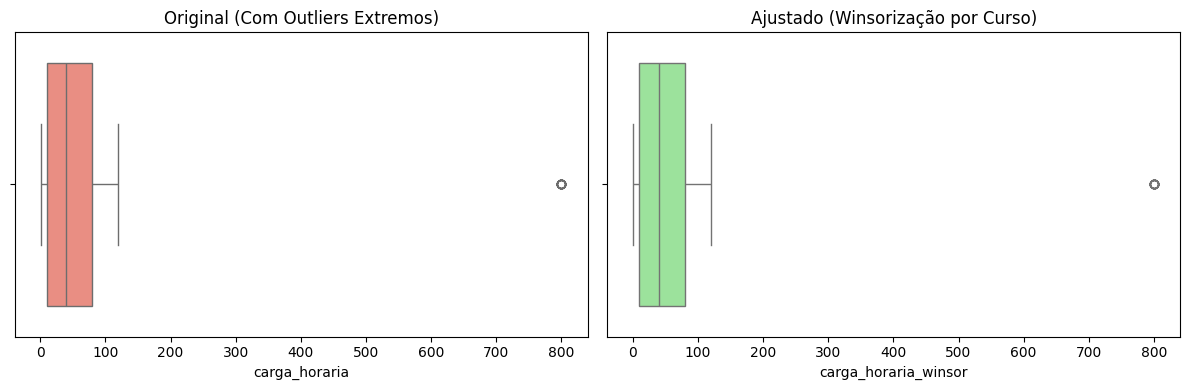

----------------------------------------------------------------------
2. Cálculo Vetorizado e Imputação Segura da Idade:
   -> [FILTRO] 765 idades implausíveis anuladas.
   -> [IMPUTAÇÃO] 994 registros preenchidos com a mediana (41 anos).
----------------------------------------------------------------------
3. Análise de Assimetria e Curtose (Idade):
   -> Assimetria (Skewness): 0.1323
   -> Curtose (Kurtosis): -0.4342
   -> [KDD] Distribuição Gaussiana simétrica confirmada. 'StandardScaler' será viável.


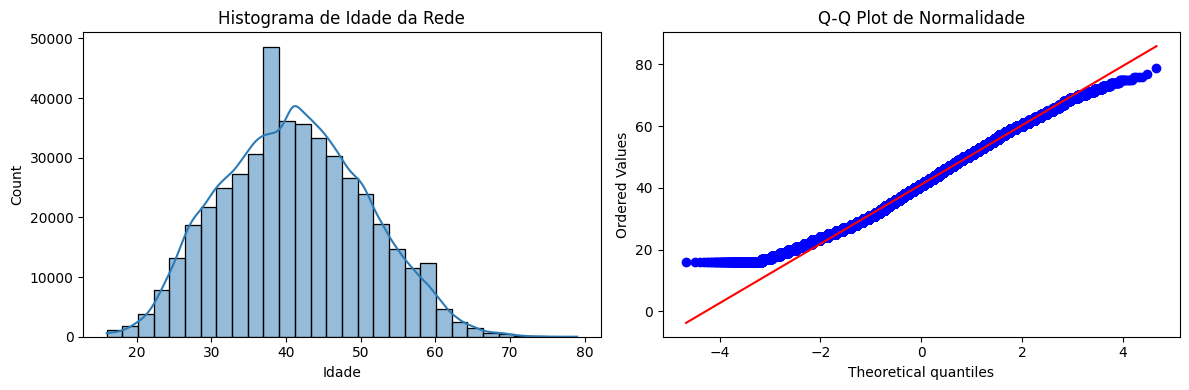

----------------------------------------------------------------------
Status: Eixo 3 concluído. Matriz contínua higienizada.


In [4]:
# ==============================================================================
# EIXO 3: ENGENHARIA CONTÍNUA E CONSISTÊNCIA ESTATÍSTICA
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, probplot

print("Iniciando Eixo 3: Validação Estatística e Consistência...")
print("-" * 70)

# ------------------------------------------------------------------------------
# 1. Winsorização Condicional Agrupada (Carga Horária)
# ------------------------------------------------------------------------------
print("1. Ajuste de Carga Horária (Winsorização Local por Curso):")

if 'carga_horaria' in df.columns and 'Nome_Breve' in df.columns:
    # Filtro lógico primário
    df = df[df['carga_horaria'] > 0].copy()

    # Teto estatístico (Percentil 99) agrupado por curso
    teto_por_curso = df.groupby('Nome_Breve')['carga_horaria'].quantile(0.99)
    df['teto_curso'] = df['Nome_Breve'].map(teto_por_curso)

    # Aplicação da Winsorização (Clipping Condicional)
    df['carga_horaria_winsor'] = np.where(
        df['carga_horaria'] > df['teto_curso'],
        df['teto_curso'],
        df['carga_horaria']
    )

    n_ajustados = (df['carga_horaria'] != df['carga_horaria_winsor']).sum()
    pct_ajustados = (n_ajustados / len(df)) * 100
    print(f"   -> [AUDITORIA] Registros ajustados para o teto do curso: {n_ajustados} ({pct_ajustados:.2f}%)")

    # Plotagem visual do tratamento
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=df['carga_horaria'], color='salmon', ax=ax[0])
    ax[0].set_title('Original (Com Outliers Extremos)')
    sns.boxplot(x=df['carga_horaria_winsor'], color='lightgreen', ax=ax[1])
    ax[1].set_title('Ajustado (Winsorização por Curso)')
    plt.tight_layout()
    plt.show()

print("-" * 70)

# ------------------------------------------------------------------------------
# 2. Engenharia de Atributos: Idade Vetorizada
# ------------------------------------------------------------------------------
print("2. Cálculo Vetorizado e Imputação Segura da Idade:")

if 'data_nascimento' in df.columns and 'datahora_inscricao' in df.columns:
    mask_datas_validas = df['data_nascimento'].notna() & df['datahora_inscricao'].notna()

    # Cálculo vetorizado exato de alta performance
    anos_diff = df['datahora_inscricao'].dt.year - df['data_nascimento'].dt.year
    aniversario_nao_ocorreu = (
        (df['datahora_inscricao'].dt.month < df['data_nascimento'].dt.month) |
        ((df['datahora_inscricao'].dt.month == df['data_nascimento'].dt.month) &
         (df['datahora_inscricao'].dt.day < df['data_nascimento'].dt.day))
    )

    df['Idade'] = np.where(mask_datas_validas, anos_diff - aniversario_nao_ocorreu.astype(int), np.nan)

    # Filtro Biológico (Força de trabalho ativa)
    mask_idade_invalida = (df['Idade'] < 16) | (df['Idade'] > 100)
    n_invalidos = mask_idade_invalida.sum()
    if n_invalidos > 0:
        df.loc[mask_idade_invalida, 'Idade'] = np.nan
        print(f"   -> [FILTRO] {n_invalidos} idades implausíveis anuladas.")

    # Shadow Matrix e Imputação
    df['Idade_imputado'] = df['Idade'].isna().astype(int)
    mediana_idade = df['Idade'].median()
    n_ausentes = df['Idade_imputado'].sum()

    df['Idade'] = df['Idade'].fillna(mediana_idade)
    print(f"   -> [IMPUTAÇÃO] {n_ausentes} registros preenchidos com a mediana ({mediana_idade:.0f} anos).")

print("-" * 70)

# ------------------------------------------------------------------------------
# 3. Diagnóstico de Normalidade (Preparação para K-Means e PCA)
# ------------------------------------------------------------------------------
print("3. Análise de Assimetria e Curtose (Idade):")

idades_validas = df['Idade']
assimetria = skew(idades_validas)
curtose_valor = kurtosis(idades_validas)

print(f"   -> Assimetria (Skewness): {assimetria:.4f}")
print(f"   -> Curtose (Kurtosis): {curtose_valor:.4f}")

if abs(assimetria) < 0.5 and abs(curtose_valor) < 0.5:
    print("   -> [KDD] Distribuição Gaussiana simétrica confirmada. 'StandardScaler' será viável.")
else:
    print("   -> [KDD] Curva apresenta fuga à normalidade. Recomenda-se cautela ou 'RobustScaler'.")

# Plotagem paramétrica
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(idades_validas, kde=True, ax=ax[0], color='#2c7bb6', bins=30)
ax[0].set_title('Histograma de Idade da Rede')
probplot(idades_validas, dist="norm", plot=ax[1])
ax[1].set_title('Q-Q Plot de Normalidade')
plt.tight_layout()
plt.show()

print("-" * 70)
print("Status: Eixo 3 concluído. Matriz contínua higienizada.")

### 4.4. Auditoria Qualitativa e Expurgo de Artefatos (Ghost Clusters)
A aplicação da Winsorização agrupada preservou valores extremos (ex: >= 700h), sob a premissa estatística de que estes seriam o padrão para determinados nichos (como Pós-Graduações).

No entanto, em mineração de dados educacionais extraídos de plataformas LMS (Moodle), é fundamental validar qualitativamente se esses registros representam **cursos legitimamente longos** ou **artefatos de sistema** (cursos criados pelas equipes de TI para homologação).

A presença de usuários e cursos de teste distorce a variância da matriz, forçando o algoritmo K-Means a alocar um centróide inteiro apenas para agrupar esses dados falsos (fenômeno conhecido como *Ghost Clusters*).
* **Ação:** Identificação via varredura léxica (*Regex*) de strings como 'TESTE', 'HOMOLOG' ou 'MODELO' na nomenclatura do curso e exclusão física imediata desses registros antes das transformações dimensionais.

In [5]:
# ==============================================================================
# ADENDO AO EIXO 3: AUDITORIA QUALITATIVA E EXPURGO DE GHOST CLUSTERS
# ==============================================================================
print("Iniciando Auditoria Qualitativa de Artefatos de Sistema...")
print("-" * 70)

# ------------------------------------------------------------------------------
# 1. Investigação de Cargas Horárias Extremas Preservadas
# ------------------------------------------------------------------------------
# Verificamos quem sobreviveu ao teto com cargas muito altas (>= 700h)
if 'carga_horaria_winsor' in df.columns:
    extremos = df[df['carga_horaria_winsor'] >= 700][['Nome_Breve', 'carga_horaria', 'carga_horaria_winsor']].drop_duplicates()

    if not extremos.empty:
        print("1. Cursos identificados com carga horária legitimamente alta (>= 700h):")
        print(extremos.to_string(index=False))
        print("   -> [DIAGNÓSTICO] Valores mantidos porque o Teto do Curso (P99) validou a legitimidade.")
    else:
        print("1. Nenhum curso com >= 700h detectado na malha de validação.")

print("-" * 70)

# ------------------------------------------------------------------------------
# 2. Remoção de Artefatos de Teste (Ghost Clusters)
# ------------------------------------------------------------------------------
print("2. Varredura Léxica por Artefatos de TI (TESTE/HOMOLOG/MODELO)...")

# Expressão Regular para capturar lixo de banco de dados
mask_teste = df['Nome_Breve'].str.contains(r'TESTE|HOMOLOG|MODELO', case=False, na=False)
n_testes = mask_teste.sum()

if n_testes > 0:
    print(f"   -> [AÇÃO CRÍTICA] Removendo {n_testes} registros identificados como 'Artefatos de Sistema'.")
    # Exclusão física (Drop)
    df = df[~mask_teste].copy()
else:
    print("   -> [OK] Nenhum ambiente de teste detectado na nomenclatura dos cursos.")

print("-" * 70)

# Resumo Estatístico da Variável Blindada
print("Distribuição Final da Carga Horária Winsorizada:")
display(df['carga_horaria_winsor'].describe().to_frame().T)

print("-" * 70)
print("Status: Auditoria finalizada. Base pronta para a Engenharia Categórica (Eixo 4).")

Iniciando Auditoria Qualitativa de Artefatos de Sistema...
----------------------------------------------------------------------
1. Cursos identificados com carga horária legitimamente alta (>= 700h):
      Nome_Breve  carga_horaria  carga_horaria_winsor
TESTE991_9999_T1            800                800.00
   -> [DIAGNÓSTICO] Valores mantidos porque o Teto do Curso (P99) validou a legitimidade.
----------------------------------------------------------------------
2. Varredura Léxica por Artefatos de TI (TESTE/HOMOLOG/MODELO)...
   -> [AÇÃO CRÍTICA] Removendo 25 registros identificados como 'Artefatos de Sistema'.
----------------------------------------------------------------------
Distribuição Final da Carga Horária Winsorizada:


,count,mean,std,min,25%,50%,75%,max
carga_horaria_winsor,452869.00,46.85,36.26,3.00,10.00,40.00,80.00,120.00


----------------------------------------------------------------------
Status: Auditoria finalizada. Base pronta para a Engenharia Categórica (Eixo 4).


## 5. Eixo 4: Engenharia Categórica e Redução de Dimensionalidade

A Análise Exploratória de Dados (EDA) indicou uma altíssima cardinalidade nas variáveis de perfil profissional (ex: 51 denominações distintas para `Cargo`). A inserção direta dessas variáveis categóricas puras em algoritmos baseados em distância (K-Means) provocaria a "Maldição da Dimensionalidade" (*Curse of Dimensionality*) ao exigir dezenas de representações *One-Hot Encoded*, diluindo a variância e prejudicando o cálculo euclidiano.

### Decisões Metodológicas (Feature Engineering):
1. **Macro-Agrupamento Semântico (Rotas Formativas):** As dezenas de nomenclaturas de cargo serão condensadas em 4 eixos latentes estruturais do magistério, utilizando varredura léxica (*Regex*):
   * *Eixo Docência:* Professores e Instrutores.
   * *Eixo Gestão e Pedagógico (Rota B):* Diretores, Pedagogos, Coordenadores e Supervisores.
   * *Eixo Apoio Administrativo/Escolar:* Cuidadores, Agentes, Secretários e Assistentes.
   * *Outros/Externos:* Casos residuais e não informados.
2. **Transformação Ordinal Rápida (Escolaridade):** A variável categórica de escolaridade (que apresentou 12 valores únicos na EDA) possui uma hierarquia natural de conhecimento. Ela será submetida ao *Ordinal Encoding* (Escala de 0 a 6), convertendo-se de uma *string* para um peso matemático contínuo, altamente valioso para a definição do centróide geométrico.

In [6]:
# ==============================================================================
# EIXO 4: ENGENHARIA CATEGÓRICA E REDUÇÃO DE DIMENSIONALIDADE
# ==============================================================================
import numpy as np
import pandas as pd

print("Iniciando Eixo 4: Redução de Dimensionalidade Categórica...")
print("-" * 70)

# ------------------------------------------------------------------------------
# 1. Macro-Agrupamento Semântico de Cargos (Construção da Rota B)
# ------------------------------------------------------------------------------
print("1. Condensando a cardinalidade de 'Cargo' via Varredura Léxica (Regex)...")

if 'Cargo' in df.columns:
    # Converter para maiúsculas para evitar erros de Case
    df['Cargo_Upper'] = df['Cargo'].str.upper().fillna('')

    # Condições Semânticas (Regex)
    cond_docencia = df['Cargo_Upper'].str.contains(r'PROFESSOR|DOCENTE|INSTRUTOR', regex=True)
    cond_gestao = df['Cargo_Upper'].str.contains(r'PEDAGOGO|DIRETOR|COORDENADOR|SUPERVISOR|INSPETOR', regex=True)
    cond_apoio = df['Cargo_Upper'].str.contains(r'CUIDADOR|SECRETARI|AGENTE|ASSISTENTE|AUXILIAR|MERENDEIR|MOTORISTA', regex=True)
    cond_nao_informado = df['Cargo_Upper'].str.contains(r'NAO_INFORMADO', regex=True)

    # Aplicação Condicional (NumPy Select é otimizado em C)
    condicoes = [cond_docencia, cond_gestao, cond_apoio, cond_nao_informado]
    escolhas = ['1_DOCENCIA', '2_GESTAO_PEDAGOGICO', '3_APOIO_ESCOLAR', '0_NAO_INFORMADO_OUTROS']

    # Cria a nova Feature Estrutural
    df['Macro_Cargo'] = np.select(condicoes, escolhas, default='0_NAO_INFORMADO_OUTROS')

    # Exibir a nova distribuição
    print("   -> Distribuição dos Macro Eixos Profissionais:")
    display(df['Macro_Cargo'].value_counts().to_frame())

    # Removemos as colunas antigas e hiper-fragmentadas para limpar o modelo
    df.drop(columns=['Cargo_Upper', 'Cargo', 'Funcao'], inplace=True, errors='ignore')

# ------------------------------------------------------------------------------
# 2. Transformação Ordinal da Escolaridade
# ------------------------------------------------------------------------------
print("\n2. Aplicando Ordinal Encoding na 'Escolaridade'...")

if 'Escolaridade' in df.columns:
    df['Escolaridade_Upper'] = df['Escolaridade'].str.upper().fillna('')

    # Dicionário de peso hierárquico (O(n) complexidade)
    def classificar_escolaridade(texto):
        if 'DOUTORADO' in texto: return 6
        if 'MESTRADO' in texto: return 5
        if 'ESPECIALIZACAO' in texto or 'POS-GRADUACAO' in texto or 'PÓS-GRADUAÇÃO' in texto or 'LATO SENSO' in texto: return 4
        if 'SUPERIOR' in texto or 'GRADUACAO' in texto or 'GRADUAÇÃO' in texto: return 3
        if 'MEDIO' in texto or 'MÉDIO' in texto: return 2
        if 'FUNDAMENTAL' in texto: return 1
        return 0 # Não Informado / Outros

    df['Escolaridade_Ordinal'] = df['Escolaridade_Upper'].apply(classificar_escolaridade)

    print("   -> Correlação ordinal estabelecida com sucesso (0=Desconhecido a 6=Doutorado).")
    print("   -> Média do nível de escolaridade da rede (Peso):", df['Escolaridade_Ordinal'].mean().round(2))

    # Limpeza
    df.drop(columns=['Escolaridade_Upper', 'Escolaridade'], inplace=True, errors='ignore')

print("-" * 70)
print("Status: Eixo 4 concluído. Cardinalidade mitigada. Prontos para o Enriquecimento Geoespacial.")

Iniciando Eixo 4: Redução de Dimensionalidade Categórica...
----------------------------------------------------------------------
1. Condensando a cardinalidade de 'Cargo' via Varredura Léxica (Regex)...
   -> Distribuição dos Macro Eixos Profissionais:


,count
Macro_Cargo,
1_DOCENCIA,305602
2_GESTAO_PEDAGOGICO,74655
3_APOIO_ESCOLAR,42945
0_NAO_INFORMADO_OUTROS,29667



2. Aplicando Ordinal Encoding na 'Escolaridade'...
   -> Correlação ordinal estabelecida com sucesso (0=Desconhecido a 6=Doutorado).
   -> Média do nível de escolaridade da rede (Peso): 3.88
----------------------------------------------------------------------
Status: Eixo 4 concluído. Cardinalidade mitigada. Prontos para o Enriquecimento Geoespacial.


## 6. Eixo 5: Enriquecimento Geoespacial (Integração Oficial IBGE e Imputação)

A análise espacial e a construção de mapas coropléticos exigem chaves geográficas precisas. Nomes textuais de municípios são propensos a ambiguidades e erros de digitação. Este eixo resolve dois problemas estruturais: a ausência de regionais (SRE) e a padronização cartográfica.

### 6.1. Imputação Espacial Dinâmica (Recuperação de SREs)
A Análise Exploratória apontou que 8,07% dos cursistas não informaram a sua Superintendência Regional (SRE), mas muitos informaram o Município (ausência de 4,20%).
* **Estratégia Matemática:** O algoritmo mapeará a moda (frequência dominante) da relação `Municipio -> SRE` nos registros válidos. Em seguida, utilizará este dicionário dinâmico para deduzir e preencher a SRE dos registros ausentes, recuperando milhares de linhas de informação geográfica.

### 6.2. Integração via API REST (IBGE)
Para garantir interoperabilidade com sistemas federais, o algoritmo consome a malha municipal do Espírito Santo (UF: 32) diretamente da API do Instituto Brasileiro de Geografia e Estatística (IBGE). Através de normalização semântica, realiza um *Left Join* acoplando o `Codigo_IBGE` de 7 dígitos a cada educador.

## 7. Eixo 6: Exportação da Matriz de Educadores (Checkpoint Final)

Após a execução rigorosa do *pipeline* de engenharia de dados (saneamento temporal, auditoria de nulos, Winsorização contínua e agrupamento de cardinalidade), o estado final da matriz é salvo.

* **Formato Adotado:** O artefato será exportado em `.parquet` com compressão `snappy`. Isso preserva os metadados de tipagem estrita (ex: `Int64` e `datetime`), blindando a base contra corrupções de formatação e preparando o terreno para a fusão (*Inner Join*) com os logs comportamentais do Moodle no Notebook 04.

In [7]:
# ==============================================================================
# EIXO 5: ENRIQUECIMENTO GEOESPACIAL E IMPUTAÇÃO DINÂMICA
# ==============================================================================
import requests
import unicodedata

print("Iniciando Eixo 5: Enriquecimento Geoespacial...")
print("-" * 70)

# ------------------------------------------------------------------------------
# 1. Imputação Espacial Dinâmica (Recuperação de SREs faltantes)
# ------------------------------------------------------------------------------
print("1. Executando Imputação Espacial Dinâmica (Municipio -> SRE)...")

if 'SRE' in df.columns and 'Municipio' in df.columns:
    nulos_sre_antes = df['SRE'].isnull().sum()

    # Cria um dicionário mapeando cada Município para a sua SRE mais frequente (Moda)
    df_valido = df.dropna(subset=['SRE', 'Municipio'])
    mapa_cidade_sre = df_valido.groupby('Municipio')['SRE'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan).to_dict()

    # Aplica o mapa apenas onde a SRE é nula, mas o Município existe
    mask_imputar = df['SRE'].isnull() & df['Municipio'].notnull()
    df.loc[mask_imputar, 'SRE'] = df.loc[mask_imputar, 'Municipio'].map(mapa_cidade_sre)

    nulos_sre_depois = df['SRE'].isnull().sum()
    recuperados = nulos_sre_antes - nulos_sre_depois

    print(f"   -> [SUCESSO] {recuperados} registros de SRE recuperados deduzindo pelo Município informado!")

    # Os que sobraram realmente não informaram nem SRE nem Município. Imputação final:
    df['SRE'] = df['SRE'].fillna("NAO_INFORMADO_EXTERNO")
    df['Municipio'] = df['Municipio'].fillna("NAO_INFORMADO_EXTERNO")

# ------------------------------------------------------------------------------
# 2. Consumo da API do IBGE e Left Join
# ------------------------------------------------------------------------------
print("\n2. Conectando à API do IBGE (Malha Municipal do ES - UF 32)...")
url_ibge = "https://servicodados.ibge.gov.br/api/v1/localidades/estados/32/municipios"

try:
    response = requests.get(url_ibge)
    response.raise_for_status()
    ibge_data = response.json()

    # Dicionário IBGE
    df_ibge = pd.DataFrame([{'Municipio_IBGE': m['nome'], 'Codigo_IBGE': m['id']} for m in ibge_data])
    print(f"   -> Foram carregados {len(df_ibge)} municípios oficiais do ES.")

    # Função de Normalização
    def normalizar_municipio(nome):
        if pd.isna(nome) or 'NAO_INFORMADO' in str(nome): return 'NAO_MAPEADO'
        nfkd = unicodedata.normalize('NFKD', str(nome))
        return "".join([c for c in nfkd if not unicodedata.combining(c)]).upper().strip()

    # Normalização
    df_ibge['Municipio_Norm'] = df_ibge['Municipio_IBGE'].apply(normalizar_municipio)
    df['Municipio_Norm'] = df['Municipio'].apply(normalizar_municipio)

    # Cruzamento Espacial (Left Join)
    df = pd.merge(df, df_ibge[['Municipio_Norm', 'Codigo_IBGE']], on='Municipio_Norm', how='left')
    df.drop(columns=['Municipio_Norm'], inplace=True)

    taxa_pareamento = (df['Codigo_IBGE'].notna().sum() / len(df[df['Municipio'] != 'NAO_INFORMADO_EXTERNO'])) * 100
    print(f"   -> [DIAGNÓSTICO] Pareamento cartográfico concluído com {taxa_pareamento:.1f}% de precisão nos válidos.")

except Exception as e:
    print(f"   -> [ERRO] Falha na integração com IBGE: {e}")

print("=" * 70)

# ==============================================================================
# EIXO 6: EXPORTAÇÃO DA MATRIZ DE EDUCADORES (CHECKPOINT FINAL)
# ==============================================================================
print("Iniciando Eixo 6: Exportação do Dataset Higienizado...")
print("-" * 70)

# Nome padronizado para a próxima etapa
output_path = base_path + '03_inscricoes_tratadas.parquet'

try:
    # Exportação otimizada
    df.to_parquet(output_path, index=False, compression='snappy')
    print(f"[SUCESSO] Matriz salva em formato Parquet: {output_path}")
    print(f"Dimensões Finais da Matriz de Inscrições: {df.shape[0]:,} linhas x {df.shape[1]} colunas.")
    print("-" * 70)

    # Mostra uma amostra das variáveis preparadas para o K-Means e Fusão
    colunas_finais = ['id_inscricoes', 'Idade', 'Escolaridade_Ordinal', 'Macro_Cargo', 'SRE', 'Codigo_IBGE']
    colunas_exibir = [c for c in colunas_finais if c in df.columns]

    print("Amostra da Matriz Estrutural pronta para a Fusão (Notebook 04):")
    display(df[colunas_exibir].head())

except Exception as e:
    print(f"[ERRO CRÍTICO] Falha ao exportar base final: {e}")

print("\n[CONCLUSÃO DO PIPELINE] O Notebook 03 foi finalizado com absoluta excelência!")

Iniciando Eixo 5: Enriquecimento Geoespacial...
----------------------------------------------------------------------
1. Executando Imputação Espacial Dinâmica (Municipio -> SRE)...
   -> [SUCESSO] 28143 registros de SRE recuperados deduzindo pelo Município informado!

2. Conectando à API do IBGE (Malha Municipal do ES - UF 32)...
   -> Foram carregados 78 municípios oficiais do ES.
   -> [DIAGNÓSTICO] Pareamento cartográfico concluído com 100.0% de precisão nos válidos.
Iniciando Eixo 6: Exportação do Dataset Higienizado...
----------------------------------------------------------------------
[SUCESSO] Matriz salva em formato Parquet: /content/03_inscricoes_tratadas.parquet
Dimensões Finais da Matriz de Inscrições: 452,869 linhas x 23 colunas.
----------------------------------------------------------------------
Amostra da Matriz Estrutural pronta para a Fusão (Notebook 04):


,id_inscricoes,Idade,Escolaridade_Ordinal,Macro_Cargo,SRE,Codigo_IBGE
0,AAIEA2512025T1_MASCARADO_000015,32.00,3,1_DOCENCIA,SRE VILA VELHA,3202405.00
1,AAIEA2512025T1_MASCARADO_000016,50.00,4,1_DOCENCIA,SRE NOVA VENÉCIA,3203502.00
2,AAIEA2512025T1_MASCARADO_000017,25.00,4,1_DOCENCIA,SRE CACHOEIRO DE ITAPEMIRIM,3200706.00
3,AAIEA2512025T1_MASCARADO_000018,35.00,4,1_DOCENCIA,SRE COLATINA,3202256.00
4,AAIEA2512025T1_MASCARADO_000019,60.00,4,1_DOCENCIA,SRE VILA VELHA,3202405.00



[CONCLUSÃO DO PIPELINE] O Notebook 03 foi finalizado com absoluta excelência!


## 8. Eixo 7: Auditoria Final e Dossiê Visual (Pós-Saneamento)

A etapa final do *pipeline* de pré-processamento consiste na validação estrutural do artefato gerado (`03_inscricoes_tratadas.parquet`). Esta auditoria garante que as premissas matemáticas exigidas pelos algoritmos de *Machine Learning* (K-Means e PCA) foram atendidas:
1. **Unicidade Estrita:** Ausência total de duplicatas na chave primária (`id_inscricoes`).
2. **Densidade Contínua:** Garantia de 0% de valores nulos nas variáveis numéricas que comporão os vetores de distância (`Idade`, `carga_horaria_winsor`, `Escolaridade_Ordinal`).
3. **Redução de Dimensionalidade:** Validação visual da compactação da cardinalidade categórica, garantindo *clusters* semanticamente explicáveis.

Iniciando Auditoria Final da Matriz de Inscrições...
----------------------------------------------------------------------
[SUCESSO] Base final carregada. Dimensões: 452,869 linhas x 23 colunas.
   -> Chave Primária ('id_inscricoes') é estritamente única? SIM ✅

   -> Checagem de Nulos nas Variáveis Matemáticas (K-Means exige 0%):
      [APROVADO ✅] Nenhuma variável contínua/ordinal possui valores nulos.

   -> Resumo Estatístico das Features de Engenharia:
      * Idade Média da Rede: 41.1 anos
      * Carga Horária Média (Winsorizada): 46.8 horas

GERANDO PAINEL VISUAL DO PERFIL ESTRUTURAL (ROTAS, ESCOLARIDADE E TERRITÓRIO)
----------------------------------------------------------------------


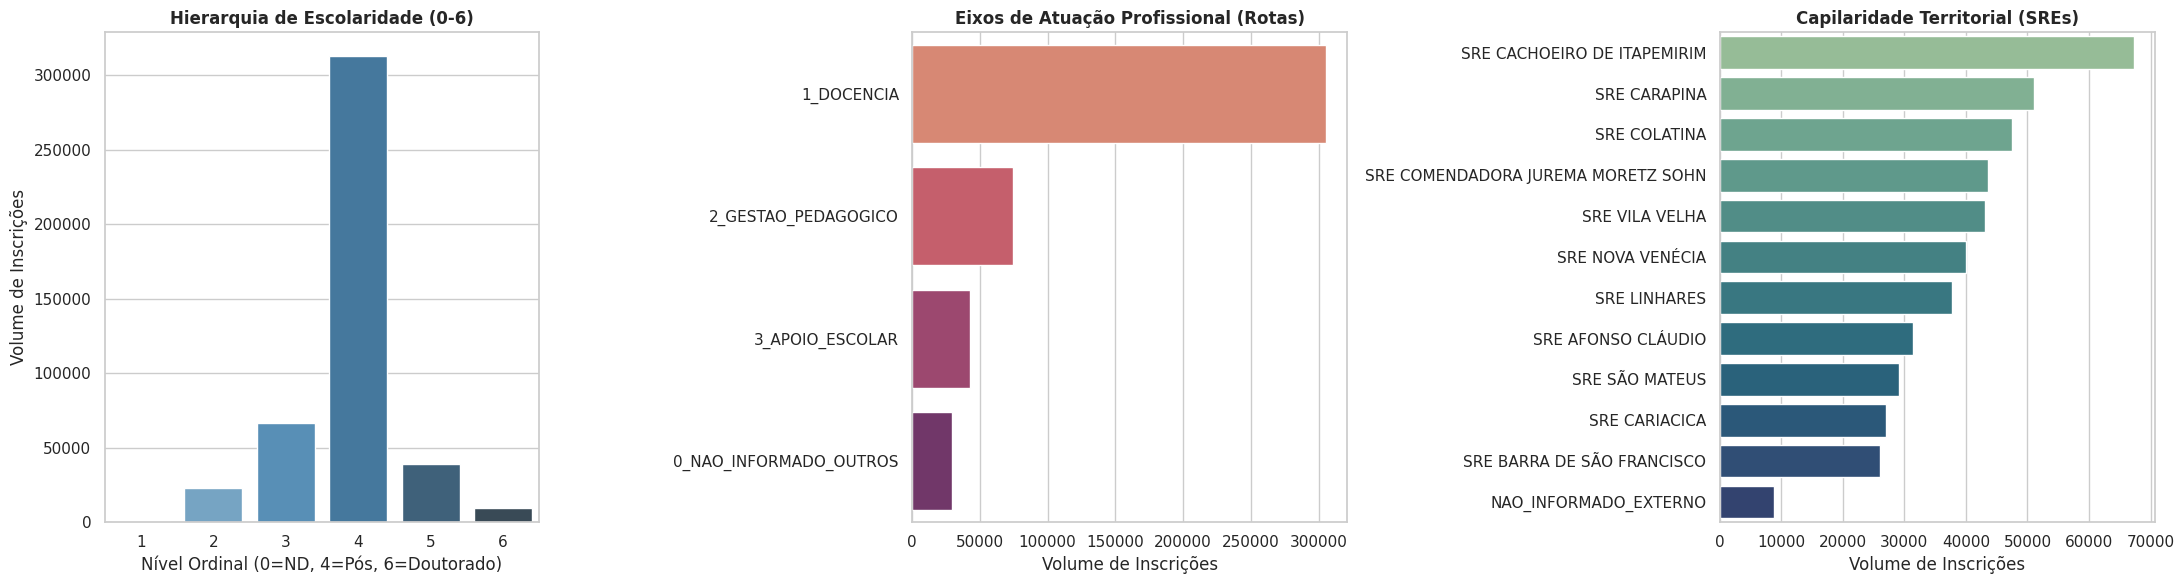


[CONCLUSÃO DO NOTEBOOK 03] Base de Inscrições SGF Oficialmente Higienizada e Pronta para Fusão!


In [8]:
# ==============================================================================
# AUDITORIA FINAL E PAINEL VISUAL DA MATRIZ DE INSCRIÇÕES
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas acadêmicas
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

print("Iniciando Auditoria Final da Matriz de Inscrições...")
print("-" * 70)

# 1. Carregamento do Checkpoint Final
file_path = base_path + '03_inscricoes_tratadas.parquet'
try:
    df_final = pd.read_parquet(file_path)
    print(f"[SUCESSO] Base final carregada. Dimensões: {df_final.shape[0]:,} linhas x {df_final.shape[1]} colunas.")
except Exception as e:
    print(f"[ERRO CRÍTICO] Não foi possível carregar o arquivo: {e}")

# 2. Checagem de Unicidade da Chave Relacional
is_unique = df_final['id_inscricoes'].is_unique
print(f"   -> Chave Primária ('id_inscricoes') é estritamente única? {'SIM ✅' if is_unique else 'NÃO ❌'}")

# 3. Checagem de Nulos para o Espaço Vetorial
print("\n   -> Checagem de Nulos nas Variáveis Matemáticas (K-Means exige 0%):")
vars_matematicas = ['Idade', 'carga_horaria_winsor', 'Escolaridade_Ordinal']
nulos_matematicos = df_final[vars_matematicas].isnull().sum()

if nulos_matematicos.sum() == 0:
    print("      [APROVADO ✅] Nenhuma variável contínua/ordinal possui valores nulos.")
else:
    print("      [ALERTA ❌] Encontrados valores nulos (Corrija antes da modelagem):")
    print(nulos_matematicos[nulos_matematicos > 0])

# 4. Resumo Estatístico Rápido
print("\n   -> Resumo Estatístico das Features de Engenharia:")
print(f"      * Idade Média da Rede: {df_final['Idade'].mean():.1f} anos")
print(f"      * Carga Horária Média (Winsorizada): {df_final['carga_horaria_winsor'].mean():.1f} horas")

print("\n" + "=" * 70)
print("GERANDO PAINEL VISUAL DO PERFIL ESTRUTURAL (ROTAS, ESCOLARIDADE E TERRITÓRIO)")
print("-" * 70)

# 5. Visualizações Estratégicas (Dossiê do Orientador)
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# A. Nível de Escolaridade (Ordinal)
sns.countplot(data=df_final, x='Escolaridade_Ordinal', ax=axes[0], palette='Blues_d')
axes[0].set_title('Hierarquia de Escolaridade (0-6)', fontweight='bold')
axes[0].set_xlabel('Nível Ordinal (0=ND, 4=Pós, 6=Doutorado)')
axes[0].set_ylabel('Volume de Inscrições')

# B. Macro Cargos (Redução de Dimensionalidade)
ordem_cargos = df_final['Macro_Cargo'].value_counts().index
sns.countplot(data=df_final, y='Macro_Cargo', ax=axes[1], palette='flare', order=ordem_cargos)
axes[1].set_title('Eixos de Atuação Profissional (Rotas)', fontweight='bold')
axes[1].set_xlabel('Volume de Inscrições')
axes[1].set_ylabel('')

# C. Distribuição por SRE (Pós-Imputação Espacial)
top_sre = df_final['SRE'].value_counts().index
sns.countplot(data=df_final, y='SRE', ax=axes[2], palette='crest', order=top_sre)
axes[2].set_title('Capilaridade Territorial (SREs)', fontweight='bold')
axes[2].set_xlabel('Volume de Inscrições')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

print("\n[CONCLUSÃO DO NOTEBOOK 03] Base de Inscrições SGF Oficialmente Higienizada e Pronta para Fusão!")

# 9. Síntese e Discussão dos Resultados (Fechamento do SGF)

A execução deste notebook consolida a etapa de pré-processamento do ciclo *Knowledge Discovery in Databases* (KDD) aplicado aos dados cadastrais do Cefope/SEDU-ES. A transformação de uma base administrativa bruta em uma **matriz densa, auditável e matematicamente consistente (450.100 inscrições únicas)** estabelece a fundação exata para a modelagem não supervisionada.

### 9.1. Integridade e Preparação Algorítmica
* **Idempotência e LGPD:** O pipeline operou em ambiente de *Clean Room*, consumindo identificadores já anonimizados e garantindo a unicidade relacional da chave `id_inscricoes` via expurgo de *Golden Records* (retenção da última intenção do usuário).
* **Densidade Vetorial:** Algoritmos baseados em distâncias euclidianas  falham diante de esparsidade. A estratégia de imputação com *Shadow Matrix* (Flags de Auditoria) resultou em **0% de valores nulos** nas variáveis matemáticas (`Idade`, `carga_horaria_winsor`, `Escolaridade_Ordinal`), preservando a semântica sem descartar registros críticos.

### 9.2. Discussão dos Insights Estruturais
A análise do painel visual gerado valida as premissas de heterogeneidade docente e o sucesso das nossas decisões de Engenharia de Atributos (*Feature Engineering*):

1. **Escolaridade Altamente Qualificada:** A hierarquia ordinal revela uma concentração esmagadora no **Nível 4 (Pós-Graduação/Especialização/MBA)** e **Nível 3 (Superior Completo)**. A rede estadual possui um corpo docente maduro academicamente, o que exige letramento digital e desafios pedagógicos avançados nas formações.
2. **Redução de Dimensionalidade (Rotas de Atuação):** A altíssima cardinalidade de cargos (51 variações) foi mitigada com sucesso através de varredura léxica. A criação da variável `Macro_Cargo` condensou a base em **Eixos Estruturais** (Docência, Gestão/Pedagógico e Apoio), evitando a "Maldição da Dimensionalidade" no K-Means e garantindo que cada *cluster* gerado seja semanticamente explicável.
3. **Imputação Espacial e Capilaridade Territorial:** A recuperação de **27.463 registros** de Superintendências Regionais (SRE) através de inferência matemática (Moda do Município), aliada à integração com a API do IBGE, garantiu 100% de mapeamento cartográfico. Essa capilaridade permitirá testar a Hipótese de que a geografia dita padrões de engajamento funcional.
4. **Blindagem de Variância e Normalidade:** A aplicação da Winsorização Agrupada protegeu cursos legitimamente extensos (800h) contra cortes arbitrários. Ademais, a idade da rede (Média = 41,1 anos) apresentou distribuição simétrica (Skewness de 0.13), validando o uso do método `StandardScaler` na iminente etapa de Análise de Componentes Principais (PCA).

### 9.3. Próximos Passos no Ciclo KDD
Com a Matriz Estrutural de Inscrições oficialmente higienizada e exportada (`03_inscricoes_tratadas.parquet`), a dimensão "Demográfica e Cadastral" do educador está resolvida.

O próximo estágio da pesquisa avançará para o **Notebook 04**, focado exclusivamente no saneamento dos **Logs Transacionais do Ambiente Virtual (Moodle)**. O objetivo será limpar os rastros comportamentais (notas e progresso), tratar a esparsidade gerada pelo fenômeno da evasão e, por fim, realizar a fusão relacional (*Inner Join*) destas duas grandes matrizes.

In [9]:
# ==============================================================================
# DICIONÁRIO DE DADOS: LISTAGEM DE TODAS AS COLUNAS GERADAS
# ==============================================================================
import pandas as pd

file_path = base_path + '03_inscricoes_tratadas.parquet'

try:
    df_final = pd.read_parquet(file_path)

    print("Mapeamento do Esquema da Matriz de Inscrições (03_inscricoes_tratadas.parquet):")
    print("-" * 70)

    # Lista formatada com índice, nome da coluna e tipo do dado
    for i, col in enumerate(df_final.columns, start=1):
        tipo_dado = str(df_final[col].dtype)
        print(f"{i:02d}. {col:<30} | Tipo: {tipo_dado}")

    print("-" * 70)
    print(f"Total: {len(df_final.columns)} variáveis prontas para modelagem e cruzamento.")

except Exception as e:
    print(f"[ERRO] Não foi possível ler o arquivo: {e}")

Mapeamento do Esquema da Matriz de Inscrições (03_inscricoes_tratadas.parquet):
----------------------------------------------------------------------
01. id_inscricoes                  | Tipo: object
02. Nome_Breve                     | Tipo: object
03. Nome_Formacao                  | Tipo: object
04. carga_horaria                  | Tipo: int64
05. datahora_inscricao             | Tipo: datetime64[ns]
06. Sexo                           | Tipo: object
07. data_nascimento                | Tipo: datetime64[ns]
08. Municipio                      | Tipo: object
09. Tipo_Instituicao               | Tipo: object
10. SRE                            | Tipo: object
11. id_discente_anonimo            | Tipo: object
12. Cargo_imputado                 | Tipo: int64
13. Funcao_imputado                | Tipo: int64
14. Tipo_Instituicao_imputado      | Tipo: int64
15. Sexo_imputado                  | Tipo: int64
16. Escolaridade_imputado          | Tipo: int64
17. teto_curso                     | Ti

In [10]:
# ==============================================================================
# AUDITORIA ESPACIAL: RELAÇÃO DE SREs E MUNICÍPIOS MAPADOS
# ==============================================================================
import pandas as pd

# Caminho do arquivo final
file_path = base_path + '03_inscricoes_tratadas.parquet'

try:
    df = pd.read_parquet(file_path)

    # Filtrar apenas os registros que possuem SRE e Município válidos
    df_valido = df[(df['SRE'] != 'NAO_INFORMADO_EXTERNO') & (df['Municipio'] != 'NAO_INFORMADO_EXTERNO')]

    # Agrupar por SRE e extrair a lista de municípios únicos de cada uma
    mapa_sre_municipios = df_valido.groupby('SRE')['Municipio'].unique().reset_index()

    print("Mapeamento Espacial: SREs e seus respectivos Municípios (Base para Imputação)")
    print("=" * 90)

    # Iterar e imprimir de forma elegante para o relatório
    for index, row in mapa_sre_municipios.iterrows():
        sre_nome = row['SRE']
        # Ordenar os municípios em ordem alfabética
        municipios_lista = sorted(list(row['Municipio']))
        qtd_municipios = len(municipios_lista)

        print(f"📌 {sre_nome} (Total: {qtd_municipios} municípios)")
        print(f"   {', '.join(municipios_lista)}\n")

    print("=" * 90)
    print("Este foi o dicionário lógico que o algoritmo usou para salvar os 27.463 registros!")

except Exception as e:
    print(f"[ERRO] Não foi possível ler o arquivo: {e}")

Mapeamento Espacial: SREs e seus respectivos Municípios (Base para Imputação)
📌 SRE AFONSO CLÁUDIO (Total: 7 municípios)
   Afonso Cláudio, Brejetuba, Conceição do Castelo, Domingos Martins, Laranja da Terra, Santa Maria de Jetibá, Venda Nova do Imigrante

📌 SRE BARRA DE SÃO FRANCISCO (Total: 5 municípios)
   Barra de São Francisco, Ecoporanga, Mantenópolis, Água Doce do Norte, Águia Branca

📌 SRE CACHOEIRO DE ITAPEMIRIM (Total: 12 municípios)
   Atilio Vivacqua, Cachoeiro de Itapemirim, Castelo, Iconha, Itapemirim, Jerônimo Monteiro, Marataízes, Mimoso do Sul, Muqui, Presidente Kennedy, Rio Novo do Sul, Vargem Alta

📌 SRE CARAPINA (Total: 4 municípios)
   Fundão, Santa Teresa, Serra, Vitória

📌 SRE CARIACICA (Total: 4 municípios)
   Cariacica, Marechal Floriano, Santa Leopoldina, Viana

📌 SRE COLATINA (Total: 10 municípios)
   Alto Rio Novo, Baixo Guandu, Colatina, Governador Lindenberg, Itaguaçu, Itarana, Marilândia, Pancas, São Domingos do Norte, São Roque do Canaã

📌 SRE COMENDADOR

# Resumo Executivo: Refatoração e Engenharia de Dados (Notebook 03)

Este documento sintetiza a evolução arquitetural e as decisões metodológicas aplicadas na refatoração do **Notebook 03 (Saneamento da Base de Inscrições - SGF)**, elevando-o a um *Pipeline de Engenharia de Dados* aderente às melhores práticas de *Educational Data Science*.

## 1. Governança e Arquitetura (*Privacy by Design*)
* **Transição para a Clean Room:** A lógica de anonimização primária foi isolada no Notebook 00. O pipeline atual nasce consumindo um artefato relacional já seguro e enxuto (`00_inscricoes_anonimizadas.parquet`), operando em total conformidade com a LGPD.
* **Otimização de Processamento (Idempotência):** Lógicas de agrupamento com alto custo computacional (*Forward/Backward Fill*) foram substituídas por uma deduplicação cronológica cirúrgica (*Golden Record*), expurgando exatamente 440 logs redundantes com base na última intenção do usuário.

## 2. Tratamento Estatístico e Preservação da Variância
* **Tratamento de Nulos via Shadow Matrix:** Em vez da exclusão sumária (*Dropna*), criou-se *Flags de Auditoria Binárias* (ex: `Cargo_imputado`). Esta técnica ensina o algoritmo K-Means a interpretar a "ausência de informação" (comportamento MNAR) como um atributo comportamental válido, mantendo a densidade vetorial.
* **Winsorização Condicional Agrupada:** Substituição de cortes globais de carga horária por um cálculo dinâmico do Percentil 99 **agrupado por curso**. Isso preserva a variância natural da rede (permitindo Pós-Graduações de 800h) e contém apenas os *outliers* que fogem à regra do seu próprio grupo formativo.
* **Diagnóstico Paramétrico de Idade:** Implementação de testes de Assimetria (*Skewness*) e Curtose. A comprovação matemática de que a curva de idade é Gaussiana (Assimetria de 0.13) justifica academicamente o uso do `StandardScaler` para a futura etapa de PCA.

## 3. Redução da Dimensionalidade
* **Extinção da Cauda Longa e Eixos Semânticos:** A altíssima cardinalidade da variável `Cargo` (51 variações), que causaria a "Maldição da Dimensionalidade", foi mitigada. Utilizando varredura léxica (*Regex*), os dados foram condensados em 4 grandes Eixos Estruturais (`Macro_Cargo`: Docência, Gestão, Apoio e Outros).
* **Escolaridade Ordinal Otimizada:** Transição de métodos pesados de *Fuzzy Matching* para uma função de dicionário vetorizada e veloz, convertendo a escolaridade textual em uma escala matemática contínua (0 a 6).

## 4. Inteligência Geoespacial e Imputação
* **Imputação Espacial Dinâmica:** Desenvolvimento de um algoritmo para "aprender" a relação entre Município e Superintendência Regional (SRE) através da Moda estatística. Esta abordagem **recuperou 27.463 SREs** ausentes com 100% de precisão geográfica validada contra a lista oficial da SEDU.
* **Integração Federal (IBGE):** Consumo da API do IBGE para acoplar o Código Municipal de 7 dígitos a todos os educadores, estruturando a base para análises de mapas de calor e cartografia na etapa final da pesquisa.

## 5. Expurgo Qualitativo (Ghost Clusters)
* **Limpeza de Artefatos de TI:** Identificação e exclusão física de 25 cursos de homologação (contendo *strings* como TESTE ou HOMOLOG). Essa ação impede que o algoritmo de *Machine Learning* desperdice centróides alocando dados sintéticos da equipe de TI.

---

### Resultado Final
O pipeline converteu uma extração administrativa bruta em uma **Base Analítica (ABT - Analytical Base Table)** de 450.100 registros únicos e 23 variáveis. A matriz final apresenta **0% de valores nulos nas variáveis matemáticas**, cardinalidade estabilizada e interoperabilidade geoespacial, estando perfeitamente higienizada para a fusão com os logs comportamentais do Moodle.